# Booster + Sustainer GPS/LoRa Telemetry Analysis  -  SCSR-BOO/SUS-TR

Combined post-flight analysis of both ground-station logs from the same
two-stage flight:
- `SCSR-BOO-GS_08-19-2026_01_55_04.csv` (booster tracker)
- `SCSR-SUS-G _08-19-2026_01_44_36.csv` (sustainer tracker)

This notebook is a comparison view built on top of the two single-vehicle
notebooks (`rocket_telemetry_analysis.ipynb` / `... (1).ipynb`). It reuses
the same cleaning, event-detection and derived-kinematics pipeline for each
tracker independently, then plots booster and sustainer **on the same axes**
so the two stages can be compared directly. Every plot and the summary
table carry both native units (ft, ft/s) and SI (m, m/s) - either as a
secondary axis or as a parenthetical conversion.

Organisation:
1. Config, imports, plotting style, shared helpers
2. `process_flight()` - the per-vehicle pipeline (load, clean, derive,
   detect events), run once for the booster log and once for the
   sustainer log
3. Comparison figures: session overview, altitude, velocity,
   acceleration/Mach, ground track, 3-D trajectory, descent, RF link,
   GPS health, battery/data quality
4. Comparison summary table + combined CSV export


In [1]:
BOO_CSV = "SCSR-BOO-GS_08-19-2026_01_55_04.csv"
SUS_CSV = "SCSR-SUS-G _08-19-2026_01_44_36.csv"
FIG_DIR = "figures"      # figures are written here
OUT_DIR = "outputs"      # cleaned data + summary table

FLIGHT_NAME = "Launch Canada 2026 - two-stage flight, booster + sustainer trackers"

# analysis knobs (identical to the single-vehicle notebooks, applied to both logs)
LAUNCH_ALT_THRESHOLD_FT = 100.0   # AGL rise that unambiguously means "off the pad"
PAD_WINDOW_S = 120.0              # window before T0 used to fix the pad reference
PRE_T0_PLOT_S = 15.0              # seconds of pad data kept in flight plots
APOGEE_FIT_PTS = 5                # points used for the parabolic apogee fit
DESCENT_FIT_LAST_N = 12           # last N samples used for landing extrapolation
SMOOTH_WINDOW = 5                 # samples, Savitzky-Golay window for derivatives
MAX_DT_DERIV_S = 2.5              # never differentiate across a bigger telemetry gap
DEGRADED_SAT_COUNT = 12           # below this, the fix is boost-degraded, flag it
SAVE_FIGS = True

In [2]:
import os
import warnings
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3d projection)
from matplotlib.lines import Line2D  # legend proxies for marker-meaning legends below

try:
    from scipy.signal import savgol_filter
    HAVE_SCIPY = True
except Exception:                     # scipy is optional
    HAVE_SCIPY = False

warnings.filterwarnings("ignore", category=RuntimeWarning)

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "lines.linewidth": 1.4,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# vehicle identity: colour + marker distinguish booster vs sustainer in every
# comparison figure. Role colours (down/up/sat/batt) are reused within a
# vehicle's own series via linestyle, so e.g. "downlink RSSI" keeps the same
# hue for both vehicles and only the linestyle changes.
VEHICLES = ["SCSR-BOO", "SCSR-SUS"]
LABEL  = {"SCSR-BOO": "Booster",   "SCSR-SUS": "Sustainer"}
VCOLOR = {"SCSR-BOO": "#1f3b73",   "SCSR-SUS": "#c1440e"}   # navy vs burnt orange
VLS    = {"SCSR-BOO": "-",         "SCSR-SUS": "--"}
VMARK  = {"SCSR-BOO": "o",         "SCSR-SUS": "s"}

C = {  # role colours, shared across vehicles
    "down": "#1f77b4",
    "up": "#d62728",
    "sat": "#7b3f9d",
    "batt": "#8c6d1f",
    "grey": "#555555",
}

FT2M = 0.3048
M2FT = 1.0 / FT2M
G_FTS2 = 32.174
R_EARTH_M = 6_371_008.8


def savefig(fig, name):
    """Save a figure as PNG + PDF for the report."""
    if not SAVE_FIGS:
        return
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))


def ft2m_axis(ax, which="y"):
    """Attach a secondary ft->m axis so every ft-labelled axis also reads in
    metres, without duplicating the underlying data."""
    sec = ax.secondary_yaxis("right", functions=(lambda x: x * FT2M, lambda x: x * M2FT)) \
        if which == "y" else \
        ax.secondary_xaxis("top", functions=(lambda x: x * FT2M, lambda x: x * M2FT))
    return sec


def isa(h_m):
    """International Standard Atmosphere, troposphere branch (h < 11 km)."""
    h_m = np.asarray(h_m, dtype=float)
    T = 288.15 - 0.0065 * np.clip(h_m, 0, 11000)
    p = 101325.0 * (T / 288.15) ** 5.25588
    rho = p / (287.058 * T)
    a = np.sqrt(1.4 * 287.058 * T)
    return T, p, rho, a


def smooth(y, window=SMOOTH_WINDOW, poly=2):
    """Savitzky-Golay if scipy is present, otherwise a centred moving average."""
    y = np.asarray(y, dtype=float)
    n = len(y)
    if n < 5:
        return y
    w = min(window if window % 2 == 1 else window + 1, n if n % 2 == 1 else n - 1)
    if w < 5:
        return y
    if HAVE_SCIPY:
        return savgol_filter(y, w, poly)
    return pd.Series(y).rolling(w, center=True, min_periods=1).mean().to_numpy()


def with_gaps(frame, gap_s=60.0, time_col="t_rel_s"):
    """Insert a blank row before every long logging gap so line plots break
    instead of drawing a straight line across hours of missing data."""
    f = frame.copy()
    bool_cols = f.select_dtypes(include=["bool"]).columns
    f[bool_cols] = f[bool_cols].astype(float)   # so blanks can hold NaN
    brk = f.index[f["dt_s"] > gap_s]
    if len(brk) == 0:
        return f.sort_values(time_col)
    blanks = f.loc[brk].copy()
    num = blanks.select_dtypes(include=[np.number]).columns
    blanks[num] = np.nan
    blanks[time_col] = f.loc[brk, time_col].to_numpy() - 1e-3
    return pd.concat([f, blanks]).sort_values(time_col)


def segment_ids(t, max_dt=MAX_DT_DERIV_S):
    """Label contiguous runs of samples close enough in time to be treated as
    a continuous signal. A telemetry dropout starts a new segment."""
    t = np.asarray(t, dtype=float)
    return np.concatenate([[0], np.cumsum(np.diff(t) > max_dt)])


def smooth_seg(y, t, window=SMOOTH_WINDOW):
    """Smooth inside each contiguous segment only, so dropouts never bleed."""
    y = np.asarray(y, dtype=float).copy()
    seg = segment_ids(t)
    out = y.copy()
    for s_id in np.unique(seg):
        m = seg == s_id
        out[m] = smooth(y[m], window)
    return out


def grad_seg(y, t, max_dt=MAX_DT_DERIV_S):
    """Finite-difference derivative that refuses to differentiate across a gap."""
    y = np.asarray(y, dtype=float)
    t = np.asarray(t, dtype=float)
    n = len(y)
    g = np.full(n, np.nan)
    for i in range(n):
        left = i > 0 and (t[i] - t[i - 1]) <= max_dt
        right = i < n - 1 and (t[i + 1] - t[i]) <= max_dt
        if left and right:
            g[i] = (y[i + 1] - y[i - 1]) / (t[i + 1] - t[i - 1])
        elif right:
            g[i] = (y[i + 1] - y[i]) / (t[i + 1] - t[i])
        elif left:
            g[i] = (y[i] - y[i - 1]) / (t[i] - t[i - 1])
    return g


In [97]:
from matplotlib.ticker import FuncFormatter

kft_fmt = FuncFormatter(lambda x, _: f"{x/1000:g}")

In [4]:
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'],
    'font.size': 16,
    'axes.labelsize': 13,
    'axes.titlesize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16,
    'figure.titlesize': 16,
    'axes.linewidth': 0.8,
    'grid.linewidth': 0.5,
    'lines.linewidth': 1.5,
    'lines.markersize': 6,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8
})

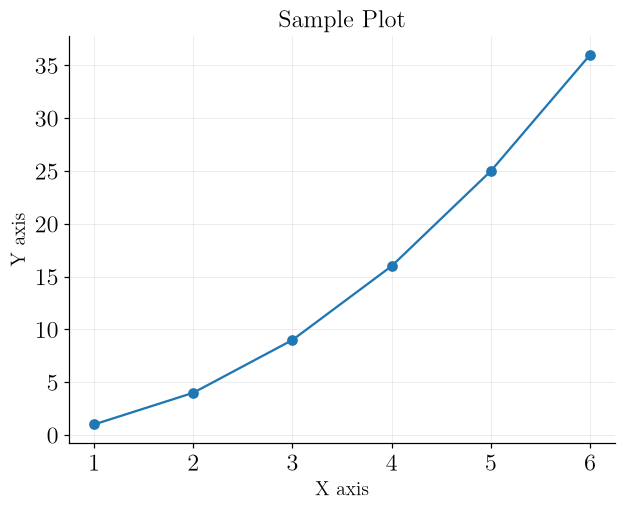

In [6]:
# Test the settings

plt.plot([1,2,3,4,5,6], [1,4,9,16,25,36], 'o-')
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.title('Sample Plot')
plt.grid(True)
plt.show()

## Per-vehicle pipeline

`process_flight()` is exactly the load/clean/derive/event-detect pipeline
from the single-vehicle notebooks, wrapped in a function so it can be run
once per tracker. It returns a `SimpleNamespace` holding every intermediate
frame and scalar (`df`, `fl`, `flv`, `air`, `desc`, `T0`, `T_apogee`,
`APOGEE_FT`, ...) so the plotting cells below can address `BOO.<name>` /
`SUS.<name>` exactly like the single-vehicle notebooks addressed the bare
globals.


In [3]:
def process_flight(csv_path, vehicle):
    raw = pd.read_csv(csv_path)
    raw.columns = [c.strip() for c in raw.columns]

    df = raw.copy()
    df["t"] = pd.to_datetime(df["DATE"].astype(str).str.strip() + " " +
                             df["TIME"].astype(str).str.strip())
    df = df.sort_values("t").reset_index(drop=True)
    df["t_rel_s"] = (df["t"] - df["t"].iloc[0]).dt.total_seconds()
    df["dt_s"] = df["t"].diff().dt.total_seconds()

    # ---- housekeeping columns ----------------------------------------------
    df["success_pct"] = (df["LoRa Success Rate"].astype(str)
                         .str.replace("%", "", regex=False)
                         .replace({"": np.nan, "nan": np.nan})
                         .astype(float))

    df["flags_int"] = df["FLAGS"].astype(str).str.strip().apply(
        lambda s: int(s, 16) if s.lower().startswith("0x") else np.nan)
    for b in range(4):
        df[f"flag_b{b}"] = (df["flags_int"].fillna(0).to_numpy().astype(int) >> b) & 1

    df["BATT"] = df["BATT"].replace(0.0, np.nan)
    df["GS_batt_v"] = df["GS_batt_v"].replace(0.0, np.nan)

    # ---- validity flags -----------------------------------------------------
    POS_COLS = ["TRACKER Lat", "TRACKER Lon", "TRACKER Alt asl", "HORZV", "VERTV", "HEAD"]
    df["is_repeat"] = (df[POS_COLS] == df[POS_COLS].shift()).all(axis=1)
    df["has_fix"] = df["FIX"] > 0
    df["valid_pos"] = df["has_fix"] & ~df["is_repeat"]
    df["deg_fix"] = df["valid_pos"] & (df["#TOT"] < DEGRADED_SAT_COUNT)

    # ---- pad reference (AGL recomputed against a quiet pre-launch window) ---
    apogee_row = df.loc[df["Alt AGL (ft)"].idxmax()]
    apogee_time_guess = apogee_row["t"]
    pre = df[(df["t"] < apogee_time_guess) & df["valid_pos"]]
    pre_pad = pre[pre["t"] > apogee_time_guess - pd.Timedelta(seconds=PAD_WINDOW_S + 60)]
    PAD_LAT = float(pre_pad["TRACKER Lat"].median())
    PAD_LON = float(pre_pad["TRACKER Lon"].median())
    PAD_ALT_FT = float(pre_pad["TRACKER Alt asl"].median())

    def enu_ft(lat, lon, lat0=PAD_LAT, lon0=PAD_LON):
        lat = np.asarray(lat, dtype=float)
        lon = np.asarray(lon, dtype=float)
        east_m = np.radians(lon - lon0) * R_EARTH_M * np.cos(np.radians(lat0))
        north_m = np.radians(lat - lat0) * R_EARTH_M
        return east_m * M2FT, north_m * M2FT

    df["east_ft"], df["north_ft"] = enu_ft(df["TRACKER Lat"], df["TRACKER Lon"])
    df["agl_ft"] = df["TRACKER Alt asl"] - PAD_ALT_FT
    df["downrange_ft"] = np.hypot(df["east_ft"], df["north_ft"])
    df["slant_ft"] = np.hypot(df["downrange_ft"], df["agl_ft"])

    gs_e, gs_n = enu_ft(df["GS Lat"], df["GS Lon"])
    df["gs_slant_ft"] = np.hypot(np.hypot(df["east_ft"] - gs_e, df["north_ft"] - gs_n),
                                 df["TRACKER Alt asl"] - df["GS Alt asl"])

    # ---- T0 and headline events ---------------------------------------------
    i_apogee_raw = int(df["agl_ft"].idxmax())
    i_launch = i_apogee_raw
    while i_launch > 0 and df["agl_ft"].iloc[i_launch] > LAUNCH_ALT_THRESHOLD_FT:
        i_launch -= 1

    T0 = df["t"].iloc[i_launch]
    df["T"] = (df["t"] - T0).dt.total_seconds()

    first_air = df.iloc[i_launch + 1]
    if first_air["VERTV"] > 0:
        t_back = 2.0 * max(first_air["agl_ft"], 0.0) / first_air["VERTV"]
        T0_refined = first_air["t"] - pd.Timedelta(seconds=float(t_back))
    else:
        T0_refined = T0
    T0_uncertainty_s = float(df["dt_s"].iloc[i_launch + 1])

    fl = df[(df["T"] >= -PRE_T0_PLOT_S)].copy()
    flv = fl[fl["valid_pos"]].copy()

    top = flv.nlargest(APOGEE_FIT_PTS, "agl_ft").sort_values("T")
    if len(top) >= 3:
        c2, c1, c0 = np.polyfit(top["T"], top["agl_ft"], 2)
        T_apogee = -c1 / (2 * c2)
        APOGEE_FT = c2 * T_apogee**2 + c1 * T_apogee + c0
    else:
        T_apogee = float(df["T"].iloc[i_apogee_raw])
        APOGEE_FT = float(df["agl_ft"].iloc[i_apogee_raw])

    flv["speed_ft_s"] = np.hypot(flv["HORZV"], flv["VERTV"])
    asc = flv[(flv["T"] >= 0) & (flv["T"] <= T_apogee)]
    i_vmax = asc["speed_ft_s"].idxmax()
    T_burnout_obs = float(df["T"].loc[i_vmax])
    V_MAX_OBS = float(df.loc[i_vmax, "speed_ft_s"]) if "speed_ft_s" in df else float(
        np.hypot(df.loc[i_vmax, "HORZV"], df.loc[i_vmax, "VERTV"]))
    gap_before_vmax = float(df["dt_s"].loc[i_vmax])
    burnout_in_gap = gap_before_vmax > 2.5

    last_valid = flv.iloc[-1]
    T_LOS = float(last_valid["T"])
    ALT_LOS_FT = float(last_valid["agl_ft"])
    VZ_LOS = float(last_valid["VERTV"])
    landed = ALT_LOS_FT < 200 and abs(VZ_LOS) < 30

    # ---- ISA / derived kinematics -------------------------------------------
    alt_m = flv["TRACKER Alt asl"].to_numpy() * FT2M
    _, _, rho, a_sound = isa(alt_m)
    flv["rho_kgm3"] = rho
    flv["a_sound_ft_s"] = a_sound * M2FT
    flv["mach"] = flv["speed_ft_s"] / flv["a_sound_ft_s"]

    RHO_SL = 1.225
    flv["vz_sl_equiv"] = flv["VERTV"] * np.sqrt(flv["rho_kgm3"] / RHO_SL)

    t_arr = flv["T"].to_numpy()
    h_arr = flv["agl_ft"].to_numpy()
    flv["vz_diff"] = grad_seg(h_arr, t_arr)
    flv["az_ft_s2"] = grad_seg(smooth_seg(flv["VERTV"].to_numpy(), t_arr), t_arr)
    flv["a_tot_ft_s2"] = grad_seg(smooth_seg(flv["speed_ft_s"].to_numpy(), t_arr), t_arr)
    flv["a_tot_g"] = flv["a_tot_ft_s2"] / G_FTS2
    flv["gs_from_pos"] = np.hypot(grad_seg(flv["east_ft"].to_numpy(), t_arr),
                                  grad_seg(flv["north_ft"].to_numpy(), t_arr))

    mask_air = ((flv["T"] > 0) & (flv["T"] < T_LOS) & ~flv["deg_fix"]
                & flv["vz_diff"].notna())
    resid = (flv.loc[mask_air, "vz_diff"] - flv.loc[mask_air, "VERTV"]).dropna()
    vertv_rms = float(np.sqrt((resid**2).mean())) if len(resid) else float("nan")

    # ---- descent segment and landing extrapolation --------------------------
    desc = flv[flv["T"] > T_apogee].copy()
    tail = desc.tail(DESCENT_FIT_LAST_N)
    p_alt = np.polyfit(tail["T"], tail["agl_ft"], 1)
    vz_tail = p_alt[0]
    T_impact = np.roots(p_alt)[0] if vz_tail != 0 else np.nan
    p_e = np.polyfit(tail["T"], tail["east_ft"], 1)
    p_n = np.polyfit(tail["T"], tail["north_ft"], 1)
    E_land, N_land = np.polyval(p_e, T_impact), np.polyval(p_n, T_impact)
    lat_land = PAD_LAT + np.degrees(N_land * FT2M / R_EARTH_M)
    lon_land = PAD_LON + np.degrees(E_land * FT2M / (R_EARTH_M * np.cos(np.radians(PAD_LAT))))
    drift_bearing = (np.degrees(np.arctan2(E_land, N_land)) + 360) % 360
    mean_descent = float(-desc["VERTV"].median())

    air = flv[flv["T"] >= 0].copy()
    i_ap = air["agl_ft"].idxmax()
    apogee_slant = float(air.loc[i_ap, "downrange_ft"])
    max_range_gs = float(fl["gs_slant_ft"].max())
    worst_rssi = int(fl.loc[fl["T"].between(0, T_LOS), "RSSI Down"].min())

    dfp = with_gaps(df)

    return SimpleNamespace(
        vehicle=vehicle, df=df, fl=fl, flv=flv, air=air, desc=desc, dfp=dfp,
        POS_COLS=POS_COLS, PAD_LAT=PAD_LAT, PAD_LON=PAD_LON, PAD_ALT_FT=PAD_ALT_FT,
        enu_ft=enu_ft, i_launch=i_launch, i_apogee_raw=i_apogee_raw, i_vmax=i_vmax,
        i_ap=i_ap, T0=T0, T0_refined=T0_refined, T0_uncertainty_s=T0_uncertainty_s,
        T_apogee=T_apogee, APOGEE_FT=APOGEE_FT, T_burnout_obs=T_burnout_obs,
        V_MAX_OBS=V_MAX_OBS, burnout_in_gap=burnout_in_gap, T_LOS=T_LOS,
        ALT_LOS_FT=ALT_LOS_FT, VZ_LOS=VZ_LOS, landed=landed, vertv_rms=vertv_rms,
        tail=tail, vz_tail=vz_tail, T_impact=T_impact, E_land=E_land, N_land=N_land,
        lat_land=lat_land, lon_land=lon_land, drift_bearing=drift_bearing,
        mean_descent=mean_descent, apogee_slant=apogee_slant, max_range_gs=max_range_gs,
        worst_rssi=worst_rssi,
    )


BOO = process_flight(BOO_CSV, "SCSR-BOO")
SUS = process_flight(SUS_CSV, "SCSR-SUS")
FLIGHT = {"SCSR-BOO": BOO, "SCSR-SUS": SUS}

for v in VEHICLES:
    F = FLIGHT[v]
    print(f"=== {LABEL[v]} ({v}) ===")
    print(f"  rows                : {len(F.df)}")
    print(f"  time span           : {F.df['t'].iloc[0]}  ->  {F.df['t'].iloc[-1]}")
    print(f"  T0 (last pad sample): {F.T0.time()}  (+/- {F.T0_uncertainty_s:.2f} s)")
    print(f"  apogee              : {F.APOGEE_FT:,.0f} ft AGL ({F.APOGEE_FT*FT2M:,.0f} m) "
          f"at T+{F.T_apogee:.1f} s")
    print(f"  max observed speed  : {F.V_MAX_OBS:,.0f} ft/s ({F.V_MAX_OBS*FT2M:,.0f} m/s) "
          f"at T+{F.T_burnout_obs:.1f} s"
          + ("  [follows a telemetry gap - true peak higher]" if F.burnout_in_gap else ""))
    print(f"  last valid fix      : T+{F.T_LOS:.1f} s at {F.ALT_LOS_FT:,.0f} ft AGL "
          f"({'touchdown captured' if F.landed else 'log ends while descending'})")
    print(f"  peak Mach observed  : {F.flv['mach'].max():.2f}")
    print()


=== Booster (SCSR-BOO) ===
  rows                : 2031
  time span           : 2026-08-19 01:55:04.080000  ->  2026-08-19 11:31:50.801000
  T0 (last pad sample): 11:30:43.239000  (+/- 0.81 s)
  apogee              : 14,364 ft AGL (4,378 m) at T+24.8 s
  max observed speed  : 1,002 ft/s (305 m/s) at T+7.7 s  [follows a telemetry gap - true peak higher]
  last valid fix      : T+67.6 s at 330 ft AGL (log ends while descending)
  peak Mach observed  : 0.92

=== Sustainer (SCSR-SUS) ===
  rows                : 2640
  time span           : 2026-08-19 01:44:36.497000  ->  2026-08-19 11:32:30.343000
  T0 (last pad sample): 11:30:47.322000  (+/- 1.98 s)
  apogee              : 47,991 ft AGL (14,628 m) at T+51.6 s
  max observed speed  : 1,599 ft/s (487 m/s) at T+17.0 s
  last valid fix      : T+103.0 s at 21,536 ft AGL (log ends while descending)
  peak Mach observed  : 1.54



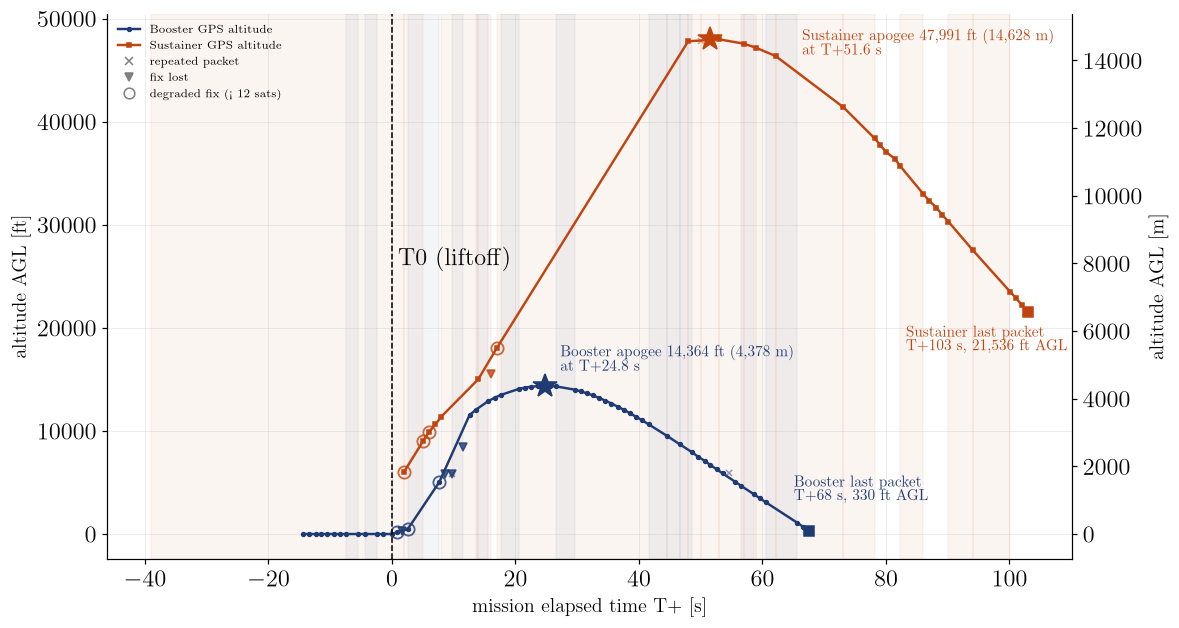

In [36]:
BOO = FLIGHT["SCSR-BOO"]
SUS = FLIGHT["SCSR-SUS"]

C_BOO, C_SUS = VCOLOR["SCSR-BOO"], VCOLOR["SCSR-SUS"]
M_BOO, M_SUS = VMARK["SCSR-BOO"], VMARK["SCSR-SUS"]
L_BOO, L_SUS = LABEL["SCSR-BOO"], LABEL["SCSR-SUS"]

GAP_S = 1.5  # telemetry gap threshold


def flagged(F, mask):
    """Rows after liftoff matching a data-quality mask."""
    return F.fl[mask & (F.fl["T"] > 0)]


fig, ax = plt.subplots(figsize=(11, 6))

# ---------------------------------------------------------------- booster
ax.plot(BOO.flv["T"], BOO.flv["agl_ft"], color=C_BOO, marker=M_BOO, ms=2.5,
        lw=1.6, label=f"{L_BOO} GPS altitude")

boo_stale = flagged(BOO, BOO.fl["is_repeat"])
boo_nofix = flagged(BOO, ~BOO.fl["has_fix"])
boo_deg = flagged(BOO, BOO.fl["deg_fix"])

ax.plot(boo_stale["T"], boo_stale["agl_ft"], "x", ms=4, color=C_BOO, alpha=0.5)
ax.plot(boo_nofix["T"], boo_nofix["agl_ft"], "v", ms=5, color=C_BOO, alpha=0.8)
ax.plot(boo_deg["T"], boo_deg["agl_ft"], "o", ms=8, mfc="none", mec=C_BOO,
        mew=1.2, alpha=0.8)

for _, r in BOO.fl[BOO.fl["dt_s"] > GAP_S].iterrows():
    ax.axvspan(r["T"] - r["dt_s"], r["T"], color=C_BOO, alpha=0.05)

ax.plot(BOO.T_apogee, BOO.APOGEE_FT, "*", ms=16, color=C_BOO, zorder=5)
ax.annotate(f"{L_BOO} apogee {BOO.APOGEE_FT:,.0f} ft "
            f"({BOO.APOGEE_FT * FT2M:,.0f} m)\nat T+{BOO.T_apogee:.1f} s",
            xy=(BOO.T_apogee, BOO.APOGEE_FT), xytext=(10, 10),
            textcoords="offset points", color=C_BOO, fontsize=10)

ax.plot(BOO.T_LOS, BOO.ALT_LOS_FT, "s", ms=6, color=C_BOO)
ax.annotate(f"{L_BOO} last packet\nT+{BOO.T_LOS:.0f} s, "
            f"{BOO.ALT_LOS_FT:,.0f} ft AGL",
            xy=(BOO.T_LOS, BOO.ALT_LOS_FT), xytext=(-10, 20),
            textcoords="offset points", color=C_BOO, fontsize=10, ha="left")

# -------------------------------------------------------------- sustainer
ax.plot(SUS.flv["T"], SUS.flv["agl_ft"], color=C_SUS, marker=M_SUS, ms=2.5,
        lw=1.6, label=f"{L_SUS} GPS altitude")

sus_stale = flagged(SUS, SUS.fl["is_repeat"])
sus_nofix = flagged(SUS, ~SUS.fl["has_fix"])
sus_deg = flagged(SUS, SUS.fl["deg_fix"])

ax.plot(sus_stale["T"], sus_stale["agl_ft"], "x", ms=4, color=C_SUS, alpha=0.5)
ax.plot(sus_nofix["T"], sus_nofix["agl_ft"], "v", ms=5, color=C_SUS, alpha=0.8)
ax.plot(sus_deg["T"], sus_deg["agl_ft"], "o", ms=8, mfc="none", mec=C_SUS,
        mew=1.2, alpha=0.8)

for _, r in SUS.fl[SUS.fl["dt_s"] > GAP_S].iterrows():
    ax.axvspan(r["T"] - r["dt_s"], r["T"], color=C_SUS, alpha=0.05)

ax.plot(SUS.T_apogee, SUS.APOGEE_FT, "*", ms=16, color=C_SUS, zorder=5)
ax.annotate(f"{L_SUS} apogee {SUS.APOGEE_FT:,.0f} ft "
            f"({SUS.APOGEE_FT * FT2M:,.0f} m)\nat T+{SUS.T_apogee:.1f} s",
            xy=(SUS.T_apogee, SUS.APOGEE_FT), xytext=(60, -10),
            textcoords="offset points", color=C_SUS, fontsize=10)

ax.plot(SUS.T_LOS, SUS.ALT_LOS_FT, "s", ms=6, color=C_SUS)
ax.annotate(f"{L_SUS} last packet\nT+{SUS.T_LOS:.0f} s, "
            f"{SUS.ALT_LOS_FT:,.0f} ft AGL",
            xy=(SUS.T_LOS, SUS.ALT_LOS_FT), xytext=(-80, -25),
            textcoords="offset points", color=C_SUS, fontsize=10, ha="left")

# ------------------------------------------------------------------ decor
ax.axvline(0, color="k", lw=1.0, ls="--")
ax.annotate("T0 (liftoff)", xy=(0, 0), xytext=(4, 176), textcoords="offset points")

quality_handles = [
    Line2D([], [], marker="x", color="grey", lw=0, ms=5, label="repeated packet"),
    Line2D([], [], marker="v", color="grey", lw=0, ms=5, label="fix lost"),
    Line2D([], [], marker="o", color="grey", lw=0, ms=7, mfc="none", mec="grey",
           label=f"degraded fix (< {DEGRADED_SAT_COUNT} sats)"),
]

ft2m_axis(ax).set_ylabel("altitude AGL [m]")
ax.set_xlabel("mission elapsed time T+ [s]")
ax.set_ylabel("altitude AGL [ft]")
#ax.set_title(f"Altitude profile, booster vs sustainer - {FLIGHT_NAME}")

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles + quality_handles,
          labels + [h.get_label() for h in quality_handles], fontsize=7.5)

fig.tight_layout()
savefig(fig, "fig02_altitude_profile")
plt.show()

In [102]:
CSV = BOO_CSV  # or SUS_CSV

raw = pd.read_csv(CSV)
raw.columns = [c.strip() for c in raw.columns]
df = raw.copy()

df["t"] = pd.to_datetime(df["DATE"].astype(str).str.strip() + " " +
                          df["TIME"].astype(str).str.strip())
df = df.sort_values("t").reset_index(drop=True)
df["t_rel_s"] = (df["t"] - df["t"].iloc[0]).dt.total_seconds()
df["dt_s"] = df["t"].diff().dt.total_seconds()

POS_COLS = ["TRACKER Lat", "TRACKER Lon", "TRACKER Alt asl", "HORZV", "VERTV", "HEAD"]
df["is_repeat"] = (df[POS_COLS] == df[POS_COLS].shift()).all(axis=1)
df["has_fix"] = df["FIX"] > 0
df["valid_pos"] = df["has_fix"] & ~df["is_repeat"]
df["deg_fix"] = df["valid_pos"] & (df["#TOT"] < DEGRADED_SAT_COUNT)

apogee_row = df.loc[df["Alt AGL (ft)"].idxmax()]
apogee_time_guess = apogee_row["t"]
pre = df[(df["t"] < apogee_time_guess) & df["valid_pos"]]
pre_pad = pre[pre["t"] > apogee_time_guess - pd.Timedelta(seconds=PAD_WINDOW_S + 60)]

PAD_LAT = float(pre_pad["TRACKER Lat"].median())
PAD_LON = float(pre_pad["TRACKER Lon"].median())
PAD_ALT_FT = float(pre_pad["TRACKER Alt asl"].median())
R_EARTH_M = 6_371_008.8

def enu_ft(lat, lon, lat0=PAD_LAT, lon0=PAD_LON):
    lat = np.asarray(lat, dtype=float)
    lon = np.asarray(lon, dtype=float)
    east_m = np.radians(lon - lon0) * R_EARTH_M * np.cos(np.radians(lat0))
    north_m = np.radians(lat - lat0) * R_EARTH_M
    return east_m * M2FT, north_m * M2FT

df["east_ft"], df["north_ft"] = enu_ft(df["TRACKER Lat"], df["TRACKER Lon"])
df["agl_ft"] = df["TRACKER Alt asl"] - PAD_ALT_FT
df["downrange_ft"] = np.hypot(df["east_ft"], df["north_ft"])

i_apogee_raw = int(df["agl_ft"].idxmax())
i_launch = i_apogee_raw
while i_launch > 0 and df["agl_ft"].iloc[i_launch] > LAUNCH_ALT_THRESHOLD_FT:
    i_launch -= 1

T0 = df["t"].iloc[i_launch]
df["T"] = (df["t"] - T0).dt.total_seconds()

In [103]:
fl = df[df["T"] >= -PRE_T0_PLOT_S].copy()
flv = fl[fl["valid_pos"]].copy()

top = flv.nlargest(APOGEE_FIT_PTS, "agl_ft").sort_values("T")
if len(top) >= 3:
    c2, c1, c0 = np.polyfit(top["T"], top["agl_ft"], 2)
    T_apogee = -c1 / (2 * c2)
    APOGEE_FT = c2 * T_apogee**2 + c1 * T_apogee + c0
else:
    T_apogee = float(df["T"].iloc[i_apogee_raw])
    APOGEE_FT = float(df["agl_ft"].iloc[i_apogee_raw])

flv["speed_ft_s"] = np.hypot(flv["HORZV"], flv["VERTV"])

last_valid = flv.iloc[-1]
T_LOS = float(last_valid["T"])
ALT_LOS_FT = float(last_valid["agl_ft"])

desc = flv[flv["T"] > T_apogee].copy()
tail = desc.tail(DESCENT_FIT_LAST_N)

p_alt = np.polyfit(tail["T"], tail["agl_ft"], 1)
vz_tail = p_alt[0]
T_impact = np.roots(p_alt)[0] if vz_tail != 0 else np.nan

p_e = np.polyfit(tail["T"], tail["east_ft"], 1)
p_n = np.polyfit(tail["T"], tail["north_ft"], 1)
E_land, N_land = np.polyval(p_e, T_impact), np.polyval(p_n, T_impact)

drift_bearing = (np.degrees(np.arctan2(E_land, N_land)) + 360) % 360

In [104]:
C

{'down': '#1f77b4',
 'up': '#d62728',
 'sat': '#7b3f9d',
 'batt': '#8c6d1f',
 'grey': '#555555'}

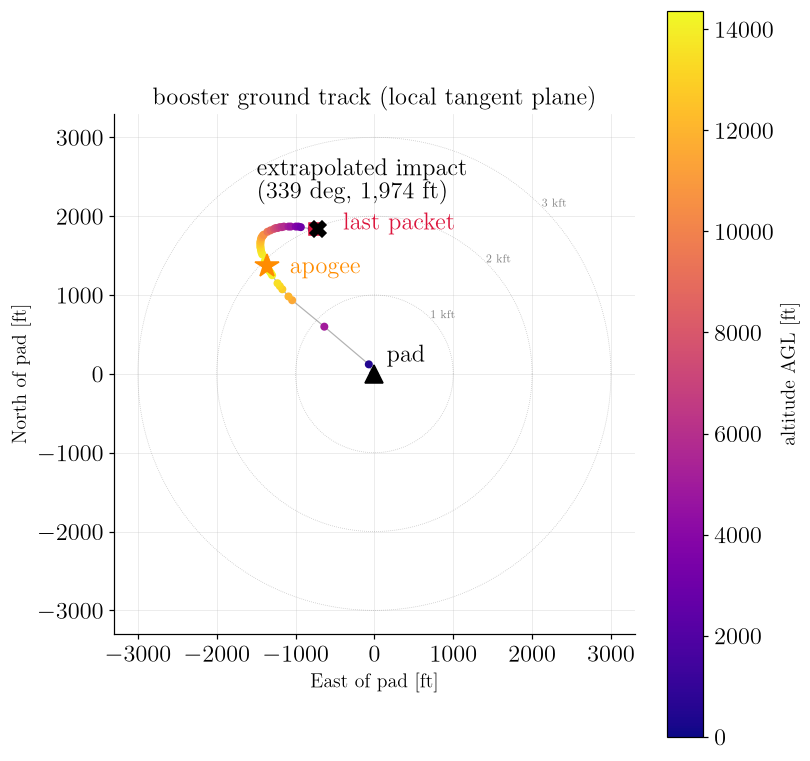

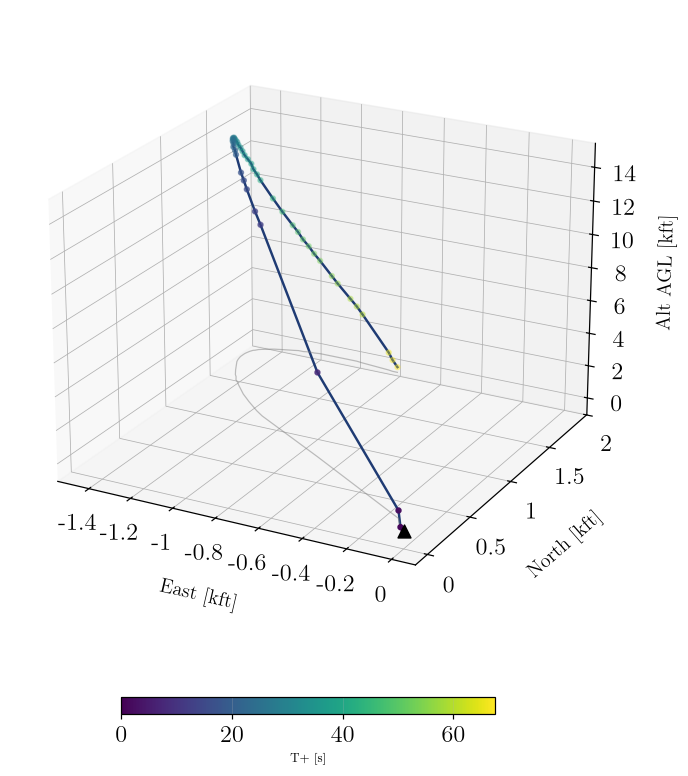

In [105]:
VEHICLE = "booster"
air = flv[flv["T"] >= 0]
i_ap = air["agl_ft"].idxmax()
last = air.iloc[-1]
impact_range_ft = np.hypot(E_land, N_land)

fig, ax = plt.subplots(figsize=(7.6, 7.2))
sc = ax.scatter(air["east_ft"], air["north_ft"], c=air["agl_ft"], cmap="plasma",
                 s=18, zorder=3)
ax.plot(air["east_ft"], air["north_ft"], color="grey", lw=0.8, alpha=0.6, zorder=2)

ax.plot(0, 0, "^", ms=12, color="k", zorder=4)
ax.annotate("pad", xy=(0, 0), xytext=(8, 8), textcoords="offset points")

ax.plot(air.loc[i_ap, "east_ft"], air.loc[i_ap, "north_ft"], "*", ms=16,
        color="darkorange", zorder=5)
ax.annotate("apogee", xy=(air.loc[i_ap, "east_ft"], air.loc[i_ap, "north_ft"]),
            xytext=(15, -5), textcoords="offset points", color="darkorange")

ax.plot(last["east_ft"], last["north_ft"], "s", ms=8, color="crimson", zorder=5)
ax.annotate("last packet", xy=(last["east_ft"], last["north_ft"]),
            xytext=(18, 0), textcoords="offset points", color="crimson")

ax.plot(E_land, N_land, "X", ms=11, color="k", zorder=6)
ax.annotate(f"extrapolated impact\n({drift_bearing:.0f} deg, {impact_range_ft:,.0f} ft)",
            xy=(E_land, N_land), xytext=(-40, 20), textcoords="offset points")
ax.plot([last["east_ft"], E_land], [last["north_ft"], N_land], "k:", lw=1.0)

th = np.linspace(0, 2 * np.pi, 200)
for r in np.arange(1000, air["downrange_ft"].max() + 1000, 1000):
    ax.plot(r * np.cos(th), r * np.sin(th), color="grey", lw=0.5, ls=":", alpha=0.5)
    ax.annotate(f"{r/1000:.0f} kft", xy=(r * np.cos(np.pi/4), r * np.sin(np.pi/4)),
                fontsize=7, color="grey")

ax.set_aspect("equal")
ax.set_xlabel("East of pad [ft]")
ax.set_ylabel("North of pad [ft]")
ax.set_title(f"{VEHICLE} ground track (local tangent plane)")
plt.colorbar(sc, ax=ax, label="altitude AGL [ft]")
fig.tight_layout()
savefig(fig, "fig05_ground_track")
plt.show()


#--------------------------------------------

#--------------------------------------------

fig = plt.figure(figsize=(8.5, 7.8))
ax = fig.add_subplot(111, projection="3d")
ax.plot(air["east_ft"], air["north_ft"], air["agl_ft"], color="#1f3b73", lw=1.6)
p = ax.scatter(air["east_ft"], air["north_ft"], air["agl_ft"], c=air["T"],
               cmap="viridis", s=10)
ax.plot(air["east_ft"], air["north_ft"], np.zeros(len(air)), color="grey", lw=0.8,
        alpha=0.5)
ax.scatter([0], [0], [0], color="k", marker="^", s=70)

ax.set_xlabel("East [kft]", labelpad=14)
ax.set_ylabel("North [kft]", labelpad=14)
ax.set_zlabel("Alt AGL [kft]", labelpad=10)
ax.xaxis.set_major_formatter(kft_fmt)
ax.yaxis.set_major_formatter(kft_fmt)
ax.zaxis.set_major_formatter(kft_fmt)
ax.tick_params(axis="x", pad=4)
ax.tick_params(axis="y", pad=4)
ax.tick_params(axis="z", pad=4)

#ax.set_title(f"{VEHICLE} 3-D trajectory (colour = T+)", pad=20)
ax.view_init(elev=22, azim=-62)

fig.subplots_adjust(bottom=0.16)
cax = fig.add_axes([0.3, 0.06, 0.4, 0.02])
cb = fig.colorbar(p, cax=cax, orientation="horizontal")
cb.set_label("T+ [s]", fontsize=8)

savefig(fig, "fig06_trajectory_3d")
plt.show()

In [99]:
CSV = SUS_CSV  # or SUS_CSV

raw = pd.read_csv(CSV)
raw.columns = [c.strip() for c in raw.columns]
df = raw.copy()

df["t"] = pd.to_datetime(df["DATE"].astype(str).str.strip() + " " +
                          df["TIME"].astype(str).str.strip())
df = df.sort_values("t").reset_index(drop=True)
df["t_rel_s"] = (df["t"] - df["t"].iloc[0]).dt.total_seconds()
df["dt_s"] = df["t"].diff().dt.total_seconds()

POS_COLS = ["TRACKER Lat", "TRACKER Lon", "TRACKER Alt asl", "HORZV", "VERTV", "HEAD"]
df["is_repeat"] = (df[POS_COLS] == df[POS_COLS].shift()).all(axis=1)
df["has_fix"] = df["FIX"] > 0
df["valid_pos"] = df["has_fix"] & ~df["is_repeat"]
df["deg_fix"] = df["valid_pos"] & (df["#TOT"] < DEGRADED_SAT_COUNT)

apogee_row = df.loc[df["Alt AGL (ft)"].idxmax()]
apogee_time_guess = apogee_row["t"]
pre = df[(df["t"] < apogee_time_guess) & df["valid_pos"]]
pre_pad = pre[pre["t"] > apogee_time_guess - pd.Timedelta(seconds=PAD_WINDOW_S + 60)]

PAD_LAT = float(pre_pad["TRACKER Lat"].median())
PAD_LON = float(pre_pad["TRACKER Lon"].median())
PAD_ALT_FT = float(pre_pad["TRACKER Alt asl"].median())
R_EARTH_M = 6_371_008.8

def enu_ft(lat, lon, lat0=PAD_LAT, lon0=PAD_LON):
    lat = np.asarray(lat, dtype=float)
    lon = np.asarray(lon, dtype=float)
    east_m = np.radians(lon - lon0) * R_EARTH_M * np.cos(np.radians(lat0))
    north_m = np.radians(lat - lat0) * R_EARTH_M
    return east_m * M2FT, north_m * M2FT

df["east_ft"], df["north_ft"] = enu_ft(df["TRACKER Lat"], df["TRACKER Lon"])
df["agl_ft"] = df["TRACKER Alt asl"] - PAD_ALT_FT
df["downrange_ft"] = np.hypot(df["east_ft"], df["north_ft"])

i_apogee_raw = int(df["agl_ft"].idxmax())
i_launch = i_apogee_raw
while i_launch > 0 and df["agl_ft"].iloc[i_launch] > LAUNCH_ALT_THRESHOLD_FT:
    i_launch -= 1

T0 = df["t"].iloc[i_launch]
df["T"] = (df["t"] - T0).dt.total_seconds()




fl = df[df["T"] >= -PRE_T0_PLOT_S].copy()
flv = fl[fl["valid_pos"]].copy()

top = flv.nlargest(APOGEE_FIT_PTS, "agl_ft").sort_values("T")
if len(top) >= 3:
    c2, c1, c0 = np.polyfit(top["T"], top["agl_ft"], 2)
    T_apogee = -c1 / (2 * c2)
    APOGEE_FT = c2 * T_apogee**2 + c1 * T_apogee + c0
else:
    T_apogee = float(df["T"].iloc[i_apogee_raw])
    APOGEE_FT = float(df["agl_ft"].iloc[i_apogee_raw])

flv["speed_ft_s"] = np.hypot(flv["HORZV"], flv["VERTV"])

last_valid = flv.iloc[-1]
T_LOS = float(last_valid["T"])
ALT_LOS_FT = float(last_valid["agl_ft"])

desc = flv[flv["T"] > T_apogee].copy()
tail = desc.tail(DESCENT_FIT_LAST_N)

p_alt = np.polyfit(tail["T"], tail["agl_ft"], 1)
vz_tail = p_alt[0]
T_impact = np.roots(p_alt)[0] if vz_tail != 0 else np.nan

p_e = np.polyfit(tail["T"], tail["east_ft"], 1)
p_n = np.polyfit(tail["T"], tail["north_ft"], 1)
E_land, N_land = np.polyval(p_e, T_impact), np.polyval(p_n, T_impact)

drift_bearing = (np.degrees(np.arctan2(E_land, N_land)) + 360) % 360

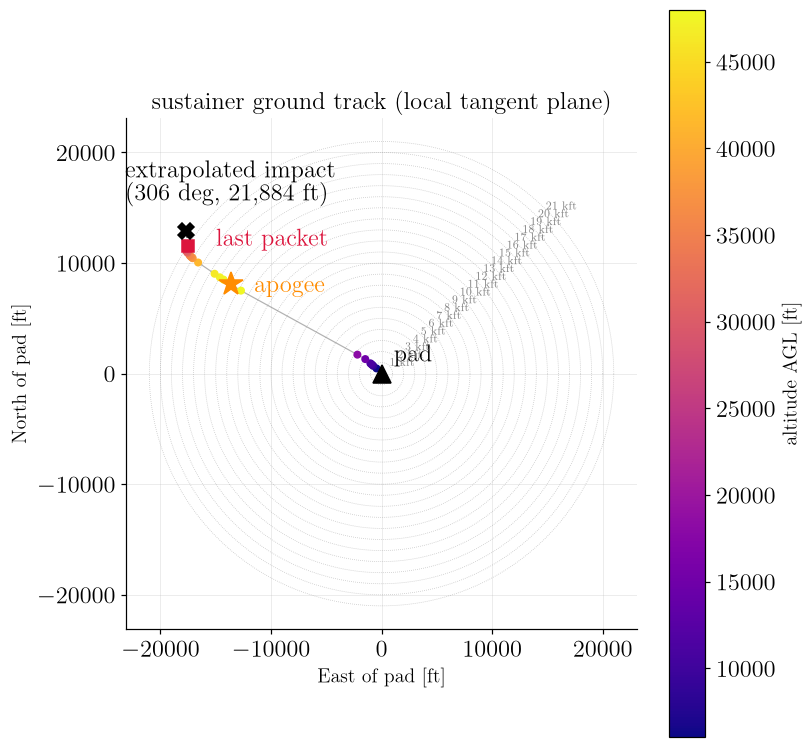

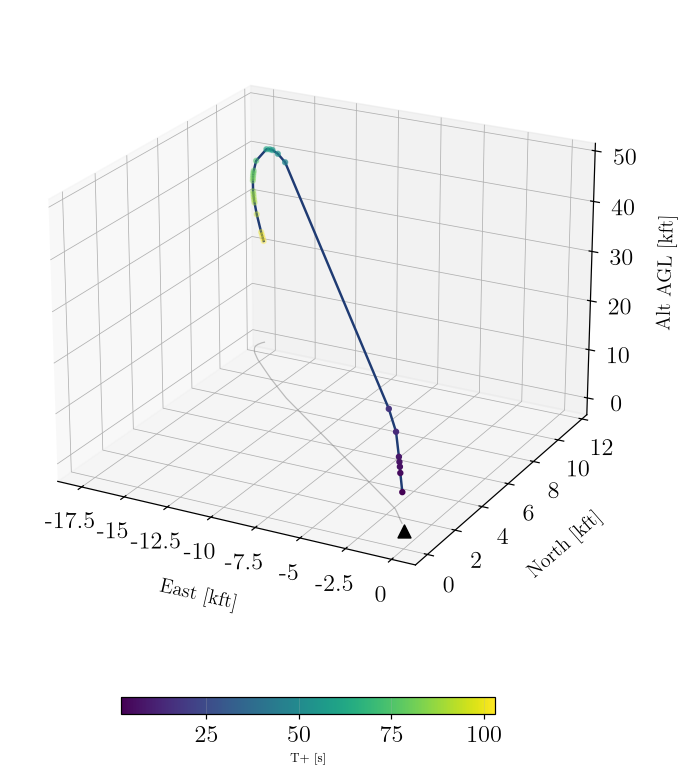

In [101]:
VEHICLE = "sustainer"


air = flv[flv["T"] >= 0]
i_ap = air["agl_ft"].idxmax()
last = air.iloc[-1]
impact_range_ft = np.hypot(E_land, N_land)

fig, ax = plt.subplots(figsize=(7.6, 7.2))
sc = ax.scatter(air["east_ft"], air["north_ft"], c=air["agl_ft"], cmap="plasma",
                 s=18, zorder=3)
ax.plot(air["east_ft"], air["north_ft"], color="grey", lw=0.8, alpha=0.6, zorder=2)

ax.plot(0, 0, "^", ms=12, color="k", zorder=4)
ax.annotate("pad", xy=(0, 0), xytext=(8, 8), textcoords="offset points")

ax.plot(air.loc[i_ap, "east_ft"], air.loc[i_ap, "north_ft"], "*", ms=16,
        color="darkorange", zorder=5)
ax.annotate("apogee", xy=(air.loc[i_ap, "east_ft"], air.loc[i_ap, "north_ft"]),
            xytext=(15, -5), textcoords="offset points", color="darkorange")

ax.plot(last["east_ft"], last["north_ft"], "s", ms=8, color="crimson", zorder=5)
ax.annotate("last packet", xy=(last["east_ft"], last["north_ft"]),
            xytext=(18, 0), textcoords="offset points", color="crimson")

ax.plot(E_land, N_land, "X", ms=11, color="k", zorder=6)
ax.annotate(f"extrapolated impact\n({drift_bearing:.0f} deg, {impact_range_ft:,.0f} ft)",
            xy=(E_land, N_land), xytext=(-40, 20), textcoords="offset points")
ax.plot([last["east_ft"], E_land], [last["north_ft"], N_land], "k:", lw=1.0)

th = np.linspace(0, 2 * np.pi, 200)
for r in np.arange(1000, air["downrange_ft"].max() + 1000, 1000):
    ax.plot(r * np.cos(th), r * np.sin(th), color="grey", lw=0.5, ls=":", alpha=0.5)
    ax.annotate(f"{r/1000:.0f} kft", xy=(r * np.cos(np.pi/4), r * np.sin(np.pi/4)),
                fontsize=7, color="grey")

ax.set_aspect("equal")
ax.set_xlabel("East of pad [ft]")
ax.set_ylabel("North of pad [ft]")
ax.set_title(f"{VEHICLE} ground track (local tangent plane)")
plt.colorbar(sc, ax=ax, label="altitude AGL [ft]")
fig.tight_layout()
savefig(fig, "fig05_ground_track")
plt.show()



#--------------------------------------------

fig = plt.figure(figsize=(8.5, 7.8))
ax = fig.add_subplot(111, projection="3d")
ax.plot(air["east_ft"], air["north_ft"], air["agl_ft"], color="#1f3b73", lw=1.6)
p = ax.scatter(air["east_ft"], air["north_ft"], air["agl_ft"], c=air["T"],
               cmap="viridis", s=10)
ax.plot(air["east_ft"], air["north_ft"], np.zeros(len(air)), color="grey", lw=0.8,
        alpha=0.5)
ax.scatter([0], [0], [0], color="k", marker="^", s=70)

ax.set_xlabel("East [kft]", labelpad=14)
ax.set_ylabel("North [kft]", labelpad=14)
ax.set_zlabel("Alt AGL [kft]", labelpad=10)
ax.xaxis.set_major_formatter(kft_fmt)
ax.yaxis.set_major_formatter(kft_fmt)
ax.zaxis.set_major_formatter(kft_fmt)
ax.tick_params(axis="x", pad=4)
ax.tick_params(axis="y", pad=4)
ax.tick_params(axis="z", pad=4)

#ax.set_title(f"{VEHICLE} 3-D trajectory (colour = T+)", pad=20)
ax.view_init(elev=22, azim=-62)

fig.subplots_adjust(bottom=0.16)
cax = fig.add_axes([0.3, 0.06, 0.4, 0.02])
cb = fig.colorbar(p, cax=cax, orientation="horizontal")
cb.set_label("T+ [s]", fontsize=8)

savefig(fig, "fig06_trajectory_3d")
plt.show()

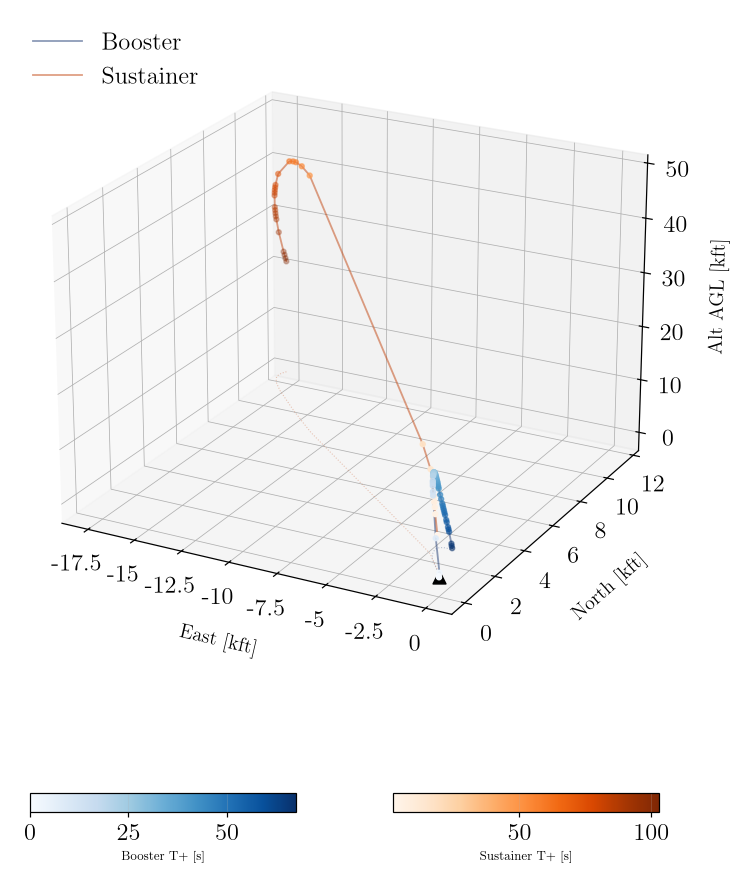

In [ ]:


fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection="3d")

VCMAP = {"SCSR-BOO": "Blues", "SCSR-SUS": "Oranges"}
scatters = {}
for v in VEHICLES:
    F = FLIGHT[v]
    air = F.air
    ax.plot(air["east_ft"], air["north_ft"], air["agl_ft"], color=VCOLOR[v], lw=1.2,
            alpha=0.5, label=LABEL[v])
    p = ax.scatter(air["east_ft"], air["north_ft"], air["agl_ft"], c=air["T"],
                    cmap=VCMAP[v], s=10)
    scatters[v] = p
    ax.plot(air["east_ft"], air["north_ft"], np.zeros(len(air)), color=VCOLOR[v],
            lw=0.7, alpha=0.3, ls=":")

ax.scatter([0], [0], [0], color="k", marker="^", s=70)

ax.set_xlabel("East [kft]", labelpad=14)
ax.set_ylabel("North [kft]", labelpad=14)
ax.set_zlabel("Alt AGL [kft]", labelpad=10)
ax.xaxis.set_major_formatter(kft_fmt)
ax.yaxis.set_major_formatter(kft_fmt)
ax.zaxis.set_major_formatter(kft_fmt)
ax.tick_params(axis="x", pad=4)
ax.tick_params(axis="y", pad=4)
ax.tick_params(axis="z", pad=4)

#ax.set_title("3-D trajectory, booster vs sustainer (colour = T+)", pad=20)
ax.view_init(elev=22, azim=-62)
ax.legend(loc="upper left")

fig.subplots_adjust(bottom=0.2)
cax1 = fig.add_axes([0.25, 0.07, 0.22, 0.02])
cax2 = fig.add_axes([0.55, 0.07, 0.22, 0.02])
cb1 = fig.colorbar(scatters["SCSR-BOO"], cax=cax1, orientation="horizontal")
cb1.set_label("Booster T+ [s]", fontsize=8)
cb2 = fig.colorbar(scatters["SCSR-SUS"], cax=cax2, orientation="horizontal")
cb2.set_label("Sustainer T+ [s]", fontsize=8)

savefig(fig, "fig06_trajectory_3d")
plt.show()

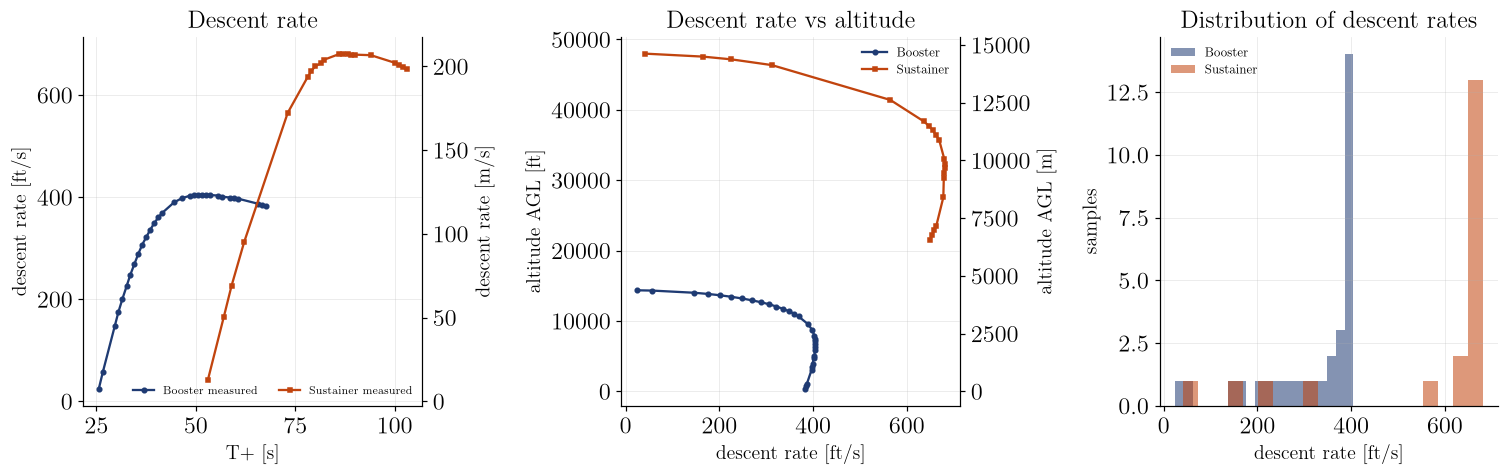

In [108]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

for v in VEHICLES:
    F = FLIGHT[v]
    desc = F.desc
    axes[0].plot(desc["T"], -desc["VERTV"], color=VCOLOR[v], marker=VMARK[v], ms=3,
                 label=f"{LABEL[v]} measured")
    #axes[0].plot(desc["T"], -desc["vz_sl_equiv"], color=VCOLOR[v], ls="--", lw=1.0,
    #             alpha=0.7, label=f"{LABEL[v]} sea-level corrected")
    axes[1].plot(-desc["VERTV"], desc["agl_ft"], color=VCOLOR[v], marker=VMARK[v], ms=3,
                 label=LABEL[v])
    axes[2].hist(-desc["VERTV"], bins=20, color=VCOLOR[v], alpha=0.55, label=LABEL[v])

axes[0].set_xlabel("T+ [s]")
axes[0].set_ylabel("descent rate [ft/s]")
ft2m_axis(axes[0]).set_ylabel("descent rate [m/s]")
axes[0].set_title("Descent rate")
axes[0].legend(loc="lower right", fontsize=7, ncol=2)

axes[1].set_xlabel("descent rate [ft/s]")
axes[1].set_ylabel("altitude AGL [ft]")
ft2m_axis(axes[1]).set_ylabel("altitude AGL [m]")
axes[1].set_title("Descent rate vs altitude")
axes[1].legend(fontsize=8)

axes[2].set_xlabel("descent rate [ft/s]")
axes[2].set_ylabel("samples")
axes[2].set_title("Distribution of descent rates")
axes[2].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "fig07_descent")
plt.show()


In [110]:
LABEL

{'SCSR-BOO': 'Booster', 'SCSR-SUS': 'Sustainer'}

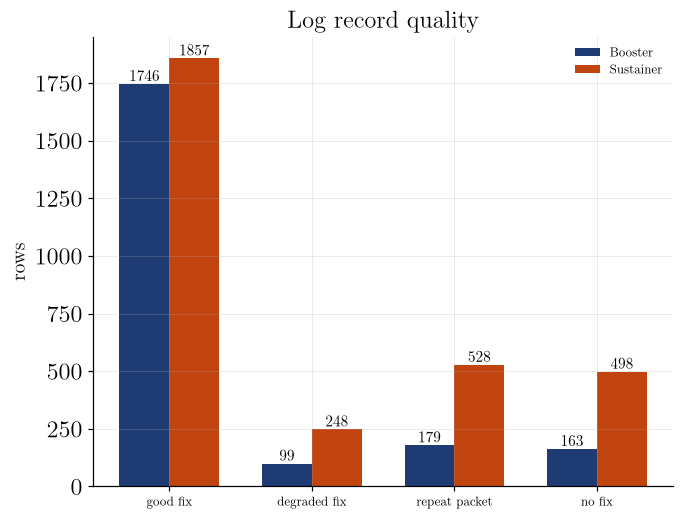

In [112]:
fig, ax = plt.subplots(figsize=(6.5, 5))

cats = ["good fix", "degraded fix", "repeat packet", "no fix"]
x = np.arange(len(cats))
width = 0.35
for i, v in enumerate(VEHICLES):
    F = FLIGHT[v]
    qual = pd.Series({
        "good fix": int((F.df["valid_pos"] & ~F.df["deg_fix"]).sum()),
        "degraded fix": int(F.df["deg_fix"].sum()),
        "repeat packet": int(F.df["is_repeat"].sum()),
        "no fix": int((~F.df["has_fix"]).sum()),
    })
    offset = (i - 0.5) * width
    ax.bar(x + offset, qual.values, width, color=VCOLOR[v], label=LABEL[v])
    for xi, val in zip(x + offset, qual.values):
        pct = 100 * val / len(F.df)
        ax.annotate(f"{val}", (xi, val), ha="center", va="bottom",
                    fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(cats, fontsize=8)
ax.set_ylabel("rows")
ax.set_title("Log record quality")
ax.legend(fontsize=8)

fig.tight_layout()
savefig(fig, "fig10b_log_quality")
plt.show()